# Diotic: overt and masked onsets, intensity-level control

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SD across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('diotic_overt_masked_onsets')

All 7 results this notebook reads are on the cluster.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-diotic_overt_masked_onsets-9200287.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 14:39:32 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 14:39:50 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
===

## Diotic (overt onsets)

<small>

**Brodbeck et al. 2020: Two talkers, overt/masked split vs plain onsets**

- Splitting onsets into overt and masked improves the fit: t_max = 6.81, p < 0.001
- About 67% of onset magnitude is overt, 33% masked

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


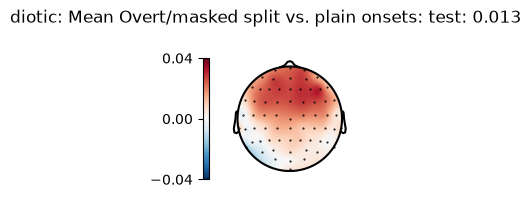

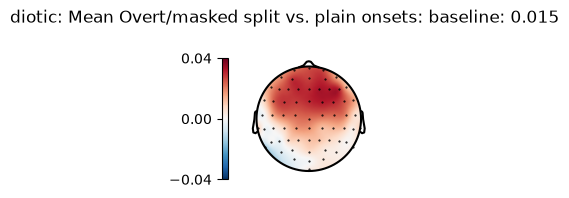

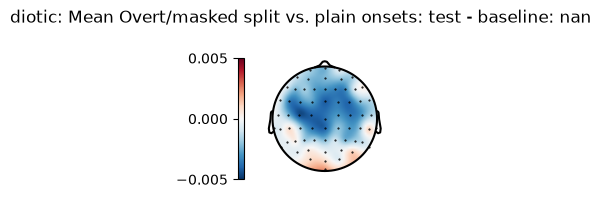

In [5]:
# Overt/masked split vs. plain onsets (diotic)
# overt/masked = the split of an onset predictor into its overt and masked half.
# Brodbeck et al. 2020 ran this comparison too: splitting onsets into overt/masked significantly improved the model overall, t = 6.81, p < .001.

# FULL_BASE   = Eatt + Oatt + Eign + Oign + Emix + Omix
# FULL_MASKED = Eatt + Oatt_overt + Oatt_masked + Eign + Oign_overt + Oign_masked + Emix + Omix
#
# Comparison: FULL_MASKED > FULL_BASE
#   (does replacing Oatt/Oign with their overt+masked split improve the
#   fit over the plain-onset model?)
#
# Full predictor names:
# FULL_MASKED (test model):
#   gammatone-8 + gammatone-on-overt-8 + gammatone-on-masked-8
#   + bg~gammatone-8 + bg~gammatone-on-overt-8 + bg~gammatone-on-masked-8
#   + mix~gammatone-8 + mix~gammatone-on-8
#
# FULL_BASE (baseline model):
#   gammatone-8 + gammatone-on-8
#   + bg~gammatone-8 + bg~gammatone-on-8
#   + mix~gammatone-8 + mix~gammatone-on-8

data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_BASE, 'diotic')
show_topomap_trio(data, diff, result, 'Overt/masked split vs. plain onsets', 'diotic', None)

In [6]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt/masked split vs. plain onsets (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, no clusters>

Overt/masked split vs. plain onsets (diotic): ROI model comparison t(12) = -4.455, p = 0.9996


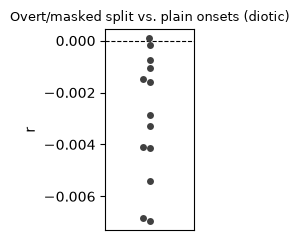

In [7]:
p = show_subject_swarm(diff, 'Overt/masked split vs. plain onsets', 'diotic')

In [8]:
# Loaded once here, reused by every STRF/peak/waveform/attention-
# effect/masking-comparison cell in both this subsection and "masked
# onset" below - same reasoning as data_full above, for FULL_MASKED.
data_masked = load_trfs_saved(FULL_MASKED, 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attend unique contribution**

- Overt attended onsets: t_max = 3.34, p = 0.027 (weaker than masked)

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


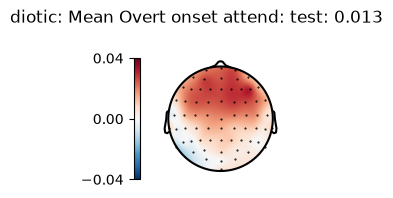

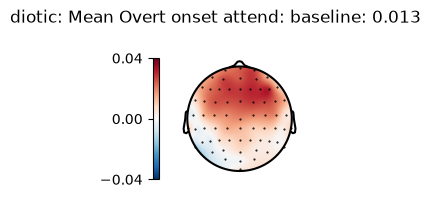

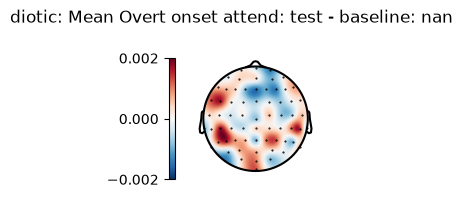

In [9]:
# Overt onset attend unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended overt onsets unique contribution, t = 3.34, p = .027.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(ATTEND), 'diotic')
show_topomap_trio(data, diff, result, 'Overt onset attend', 'diotic', overt_onset(ATTEND))

In [10]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset attend (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 3 clusters, p = .281>

Overt onset attend (diotic): ROI unique contribution t(12) = -0.506, p = 0.6889


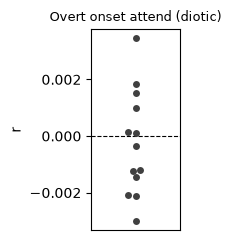

In [11]:
p = show_subject_swarm(diff, 'Overt onset attend', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset ignore unique contribution**

- Overt ignored onsets: t_max = 3.82, p = 0.016 (weaker than masked)

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


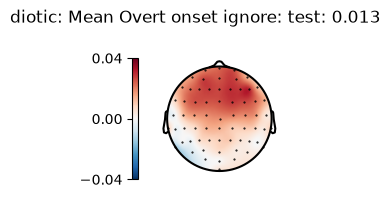

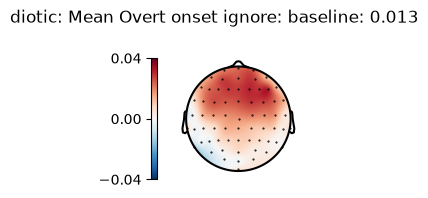

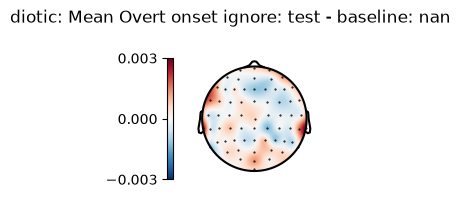

In [12]:
# Overt onset ignore unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored overt onsets unique contribution, t = 3.82, p = .016.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(IGNORE), 'diotic')
show_topomap_trio(data, diff, result, 'Overt onset ignore', 'diotic', overt_onset(IGNORE))

In [13]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset ignore (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 2 clusters, p = .137>

Overt onset ignore (diotic): ROI unique contribution t(12) = -0.342, p = 0.6308


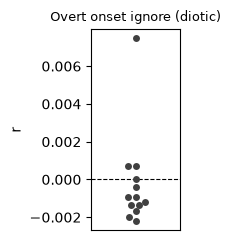

In [14]:
p = show_subject_swarm(diff, 'Overt onset ignore', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset STRFs**

- Same positive-then-negative shape
- Early positive peak: not changed by attention (may even look bigger for ignored, because the attended negative peak starts early and overlaps it)
- Only the negative peak is changed by attention (attended only)

</small>

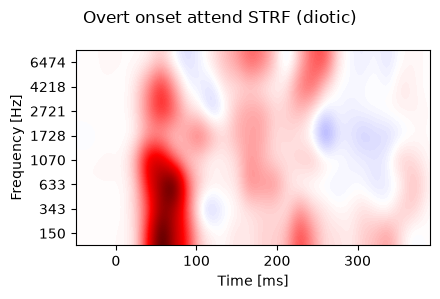

In [15]:
# Overt onset attend STRF (diotic)
strf = extract_strf(data_masked, 'gammatone_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset attend STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

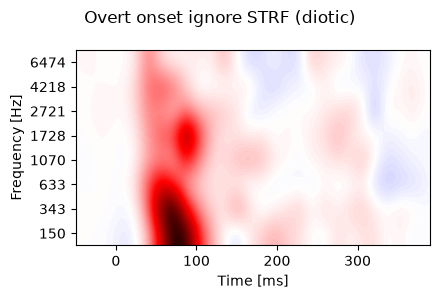

In [16]:
# Overt onset ignore STRF (diotic)
strf = extract_strf(data_masked, 'bg_gammatone_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset ignore STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset peak latencies**

- Positive peak: attended 72 ms, ignored 83 ms (mixture 72 ms)
- Negative peak: attended 133 ms (mixture 138 ms)
- Peak search window: 20 to 250 ms for the overt/masked analysis (this notebook: 40 to 200 ms)

</small>

In [17]:
# Overt onset attend peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'gammatone_on_overt_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset attend (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset attend (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset attend (diotic) positive peak: 60 ms, amp 0.003831
Overt onset attend (diotic) negative peak: 121 ms, amp -0.0003531


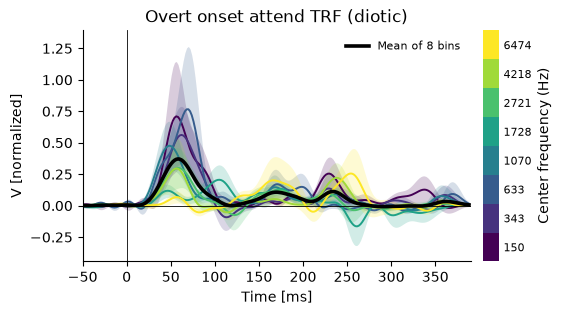

In [18]:
# Overt onset attend TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'gammatone_on_overt_8', 'Overt onset attend TRF (diotic)')

In [19]:
# Overt onset ignore peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'bg_gammatone_on_overt_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset ignore (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset ignore (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset ignore (diotic) positive peak: 72 ms, amp 0.002944
Overt onset ignore (diotic) negative peak: 190 ms, amp -0.0002431


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


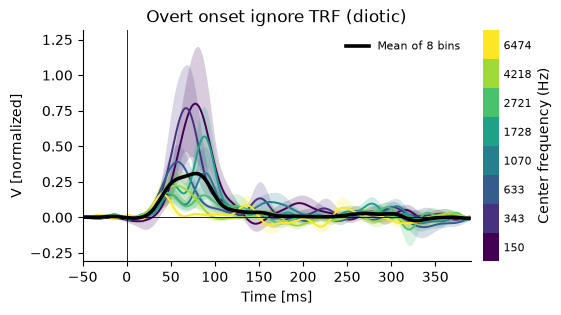

In [20]:
# Overt onset ignore TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'bg_gammatone_on_overt_8', 'Overt onset ignore TRF (diotic)')

In [21]:
# Overt onset peak comparison across attend and ignore (diotic)
dss = []
for role_name, column in (('attend', 'gammatone_on_overt_8'), ('ignore', 'bg_gammatone_on_overt_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (ignore) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


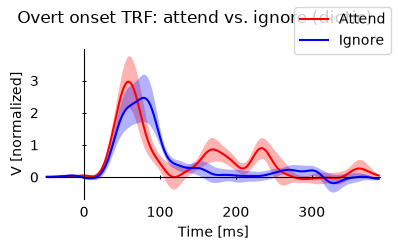

In [22]:
# The overt onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt onset TRF: attend vs. ignore (diotic)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [23]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              72     1.796e-05
02        attend              54      0.006948
03        attend              43      0.001898
04        attend              68      0.003474
05        attend              46      0.004753
06        attend              43      0.002895
07        attend              80      0.002803
08        attend              64       0.00134
09        attend              56      0.005716
10        attend              68       0.00988
11        attend              60      0.007789
12        attend              70       0.00121
13        attend              52      0.001073
01        ignore              64     2.209e-06
02        ignore              76     0.0009849
03        ignore              80      0.007596
04        ignore              62     0.0001139
05        ignore              74       0.00721
06        ignore              78     0.0008452
07        ignore              64      0.00131

In [24]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='overt onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='overt onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -2.46* p = .030


,ignore
attend,t12 = -13.37*** p < .001


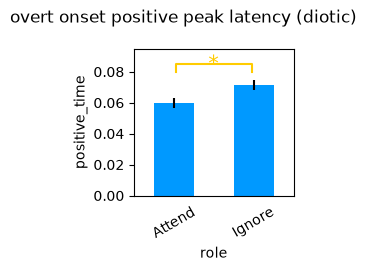

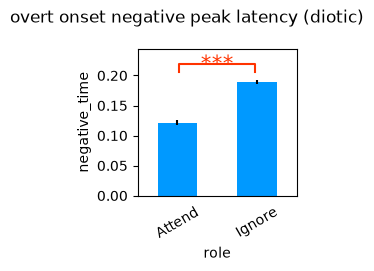

In [25]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak latency (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak latency (diotic)')
p.set_xtick_rotation(30)

In [26]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='overt onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='overt onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 0.79 p = .442


,ignore
attend,t12 = -0.32 p = .757


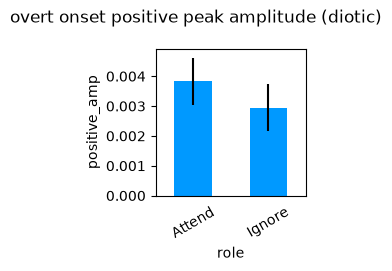

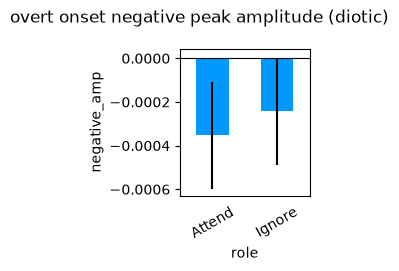

In [27]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak amplitude (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak amplitude (diotic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attention effect**

- No attention effect on the early positive peak
- Attention effect on the later negative peak, starting near the top of the positive peak

</small>

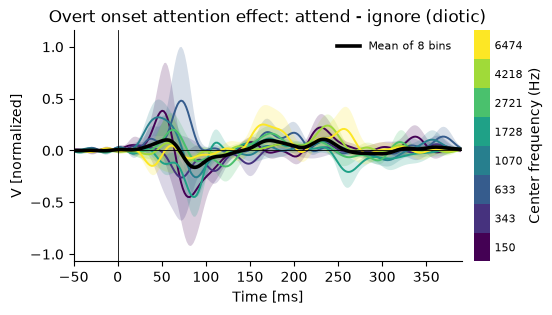

In [28]:
# Overt onset attention effect: attend - ignore (diotic)
p = plot_trf_bins(data_masked, 'gammatone_on_overt_8', 'Overt onset attention effect: attend - ignore (diotic)', subtract='bg_gammatone_on_overt_8')

## Diotic (masked onset)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attend unique contribution**

- Masked attended onsets: t_max = 8.42, p < 0.001

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


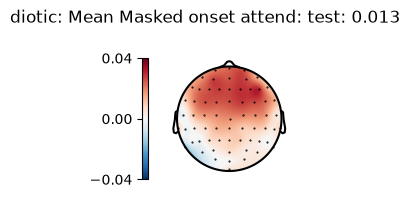

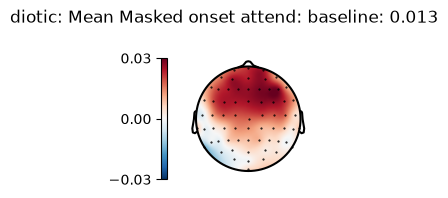

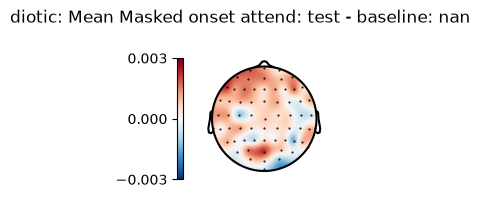

In [29]:
# Masked onset attend unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended masked onsets unique contribution, t = 8.42, p < .001 - the strongest of the four masking predictors.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(ATTEND), 'diotic')
show_topomap_trio(data, diff, result, 'Masked onset attend', 'diotic', masked_onset(ATTEND))

In [30]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset attend (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 2 clusters, p = .668>

Masked onset attend (diotic): ROI unique contribution t(12) = 0.988, p = 0.1713


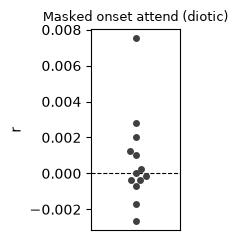

In [31]:
p = show_subject_swarm(diff, 'Masked onset attend', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset ignore unique contribution**

- Masked ignored onsets: t_max = 5.23, p < 0.001
- Key finding: the brain recovers masked onsets even for the ignored speaker

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


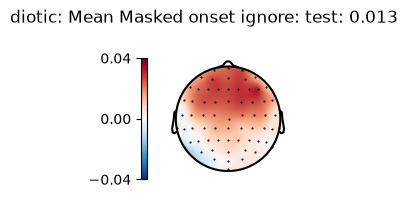

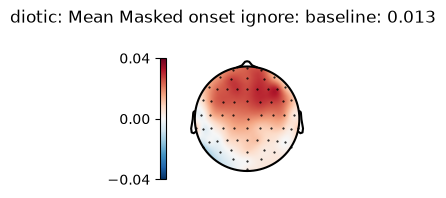

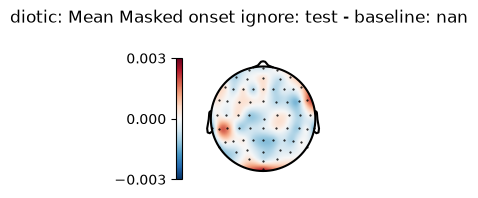

In [32]:
# Masked onset ignore unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored masked onsets unique contribution, t = 5.23, p < .001 - the brain recovers masked information even for the ignored speaker.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(IGNORE), 'diotic')
show_topomap_trio(data, diff, result, 'Masked onset ignore', 'diotic', masked_onset(IGNORE))

In [33]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset ignore (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .727>

Masked onset ignore (diotic): ROI unique contribution t(12) = -0.780, p = 0.7749


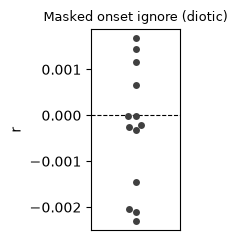

In [34]:
p = show_subject_swarm(diff, 'Masked onset ignore', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset STRFs**

- Same positive-then-negative shape, but later than overt onsets
- Even the early positive peak is bigger for the attended speaker (an early attention effect)

</small>

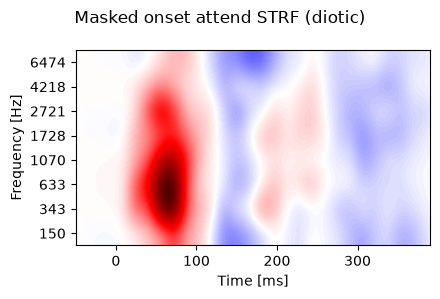

In [35]:
# Masked onset attend STRF (diotic)
strf = extract_strf(data_masked, 'gammatone_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset attend STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

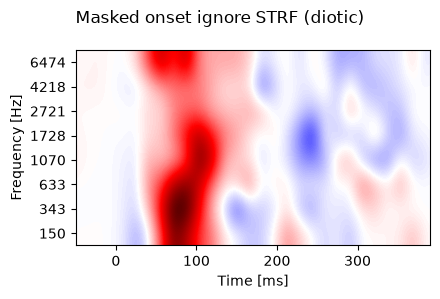

In [36]:
# Masked onset ignore STRF (diotic)
strf = extract_strf(data_masked, 'bg_gammatone_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset ignore STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset peak latencies**

- Positive peak: attended 91 ms, ignored 97 ms
- Negative peak: attended 182 ms
- Masked onsets lag overt onsets by at least 15 ms at each peak (about 20 ms on average)
- Peak search window: 20 to 250 ms (this notebook: 40 to 200 ms)

</small>

In [37]:
# Masked onset attend peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'gammatone_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset attend (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset attend (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset attend (diotic) positive peak: 65 ms, amp 0.003385
Masked onset attend (diotic) negative peak: 148 ms, amp -0.001082


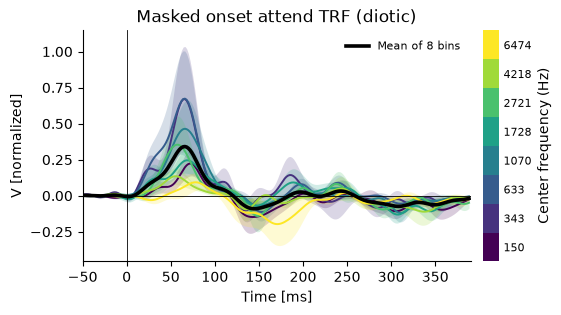

In [38]:
# Masked onset attend TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'gammatone_on_masked_8', 'Masked onset attend TRF (diotic)')

In [39]:
# Masked onset ignore peak amplitude & timing (diotic)
data = extract_trf(data_masked, 'bg_gammatone_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset ignore (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset ignore (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset ignore (diotic) positive peak: 90 ms, amp 0.002934
Masked onset ignore (diotic) negative peak: 182 ms, amp -0.0005147


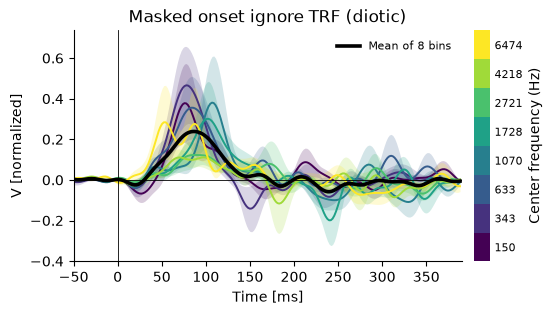

In [40]:
# Masked onset ignore TRF per frequency bin (diotic)
p = plot_trf_bins(data_masked, 'bg_gammatone_on_masked_8', 'Masked onset ignore TRF (diotic)')

In [41]:
# Masked onset peak comparison across attend and ignore (diotic)
dss = []
for role_name, column in (('attend', 'gammatone_on_masked_8'), ('ignore', 'bg_gammatone_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

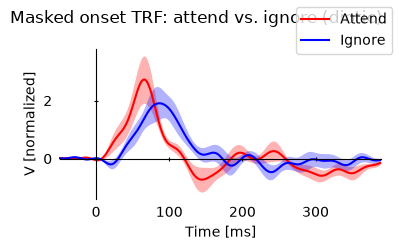

In [42]:
# The masked onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Masked onset TRF: attend vs. ignore (diotic)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [43]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              48     1.587e-06
02        attend              66      0.008618
03        attend              56       0.00189
04        attend              43      0.004467
05        attend              58       0.00757
06        attend              56      0.001032
07        attend              89     9.943e-05
08        attend              68      0.006895
09        attend              60      0.003564
10        attend              82      0.001838
11        attend              72      0.002316
12        attend              80      0.001221
13        attend              72       0.00449
01        ignore             109     3.863e-06
02        ignore             101      0.004478
03        ignore              84      0.004728
04        ignore             109     0.0004556
05        ignore              66       0.00379
06        ignore              82      0.001326
07        ignore              72      0.00100

In [44]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='masked onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='masked onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -3.50** p = .004


,ignore
attend,t12 = -5.18*** p < .001


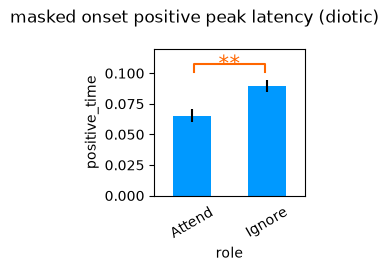

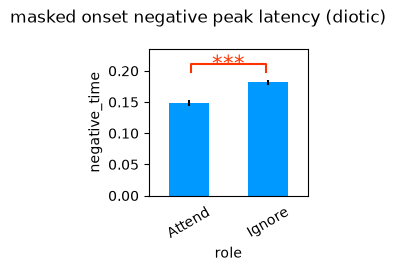

In [45]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak latency (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak latency (diotic)')
p.set_xtick_rotation(30)

In [46]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='masked onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='masked onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 0.58 p = .569


,ignore
attend,t12 = -1.23 p = .241


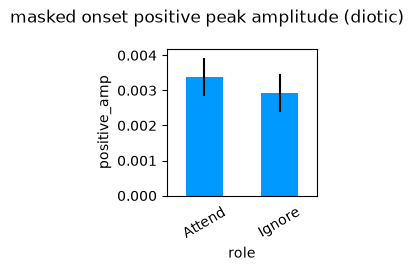

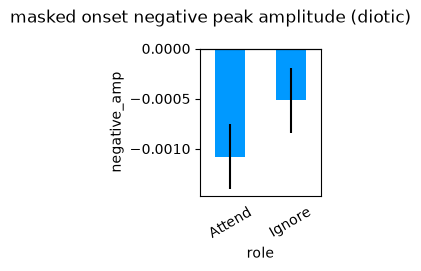

In [47]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak amplitude (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak amplitude (diotic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attention effect**

- Early positive peak bigger for attended than ignored, despite the following negative peak

</small>

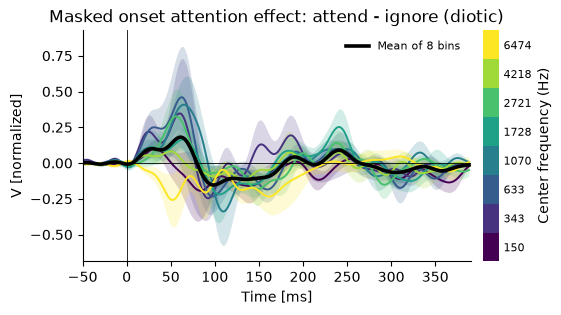

In [48]:
# Masked onset attention effect: attend - ignore (diotic)
p = plot_trf_bins(data_masked, 'gammatone_on_masked_8', 'Masked onset attention effect: attend - ignore (diotic)', subtract='bg_gammatone_on_masked_8')

<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, attended**

- Positive peak later for masked: 91 vs 72 ms, t(25) = 2.85, p = 0.009
- Negative peak later for masked: 182 vs 133 ms, t(25) = 4.45, p < 0.001

</small>

In [49]:
# Overt vs. masked peak comparison, attend (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended overt 72ms vs. attended masked 91ms (t=2.85,p=.009); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'gammatone_on_overt_8'), ('masked', 'gammatone_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

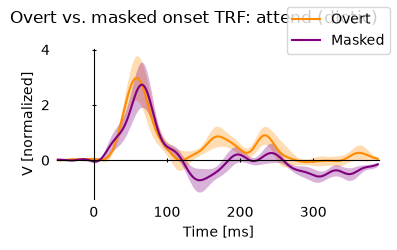

In [50]:
# Overt and masked onset TRFs of the attended speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: attend (diotic)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [51]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               72     1.796e-05
02        overt               54      0.006948
03        overt               43      0.001898
04        overt               68      0.003474
05        overt               46      0.004753
06        overt               43      0.002895
07        overt               80      0.002803
08        overt               64       0.00134
09        overt               56      0.005716
10        overt               68       0.00988
11        overt               60      0.007789
12        overt               70       0.00121
13        overt               52      0.001073
01        masked              48     1.587e-06
02        masked              66      0.008618
03        masked              56       0.00189
04        masked              43      0.004467
05        masked              58       0.00757
06        masked              56      0.001032
07        masked              89     9.943e-0

In [52]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='attend positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='attend negative peak latency: overt vs. masked'))

,masked
overt,t12 = -1.47 p = .167


,masked
overt,t12 = -4.09** p = .001


In [53]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='attend positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='attend negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = 0.44 p = .669


,masked
overt,t12 = 1.64 p = .126


<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, ignored**

- Positive peak later for masked: 97 vs 83 ms, t(25) = 6.11, p < 0.001

</small>

In [54]:
# Overt vs. masked peak comparison, ignore (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored overt 83ms vs. ignored masked 97ms (t=6.11,p<.001); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'bg_gammatone_on_overt_8'), ('masked', 'bg_gammatone_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (overt) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


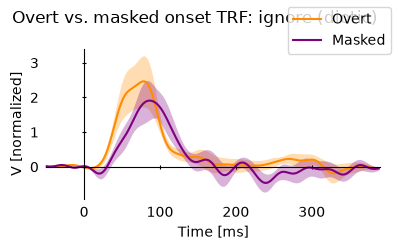

In [55]:
# Overt and masked onset TRFs of the ignored speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: ignore (diotic)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [56]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               64     2.209e-06
02        overt               76     0.0009849
03        overt               80      0.007596
04        overt               62     0.0001139
05        overt               74       0.00721
06        overt               78     0.0008452
07        overt               64      0.001317
08        overt               54      0.005895
09        overt               80      0.006143
10        overt               76      0.002044
11        overt               72      0.002438
12        overt               88      0.002432
13        overt               64      0.001256
01        masked             109     3.863e-06
02        masked             101      0.004478
03        masked              84      0.004728
04        masked             109     0.0004556
05        masked              66       0.00379
06        masked              82      0.001326
07        masked              72      0.00100

In [57]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='ignore positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='ignore negative peak latency: overt vs. masked'))

,masked
overt,t12 = -3.54** p = .004


,masked
overt,t12 = 1.61 p = .133


In [58]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='ignore positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='ignore negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = 0.02 p = .987


,masked
overt,t12 = 0.89 p = .391


<small>

**Brodbeck et al. 2020: Two talkers, stream x masking interaction**

- ANOVA on positive peak amplitude (attended/ignored x overt/masked): F(1,25) = 24.45, p < 0.001
- Overt onsets: no early attention effect; masked onsets: early attention effect

</small>

In [59]:
# Stream x masking interaction on peak amplitude (diotic)
# Brodbeck et al. 2020 ran this comparison too: stream x masking interaction, F(1,25) = 24.45, p < .001 - overt onsets show no early attention effect, masked onsets do.
dss = []
for stream_name, is_attend in (('attend', True), ('ignore', False)):
    for masking_name in ('overt', 'masked'):
        prefix = '' if is_attend else 'bg_'
        column = f'{prefix}gammatone_on_{masking_name}_8'
        ds = extract_trf(data_masked, column)
        ds[:, 'stream'] = stream_name
        ds[:, 'masking'] = masking_name
        dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by=('stream', 'masking'))
display(test.ANOVA('positive_amp', 'stream * masking * subject', data=data, title='stream x masking interaction (diotic)'))

<ANOVA: positive_amp ~ stream + masking + stream x masking + subject + stream x subject + masking x subject + stream x masking x subject
  
  stream x masking interaction (diotic)
  
                       SS   df     MS   MS(denom)   df(denom)         F      p
  ----------------------------------------------------------------------------
  stream             0.00    1   0.00        0.00          12   0.86      .373
  masking            0.00    1   0.00        0.00          12   0.16      .699
  stream x masking   0.00    1   0.00        0.00          12   0.12      .736
  ----------------------------------------------------------------------------
  Total              0.00   51
>

## Diotic (intensity-level control)

<small>

**Brodbeck et al. 2020: Two talkers, masked-aware vs level-aware model**

- The model that knows about the ignored speaker beats the loudness-tier model: t_max = 9.21, p < 0.001
- So the masked-onset effect is not just a response to quieter onsets

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


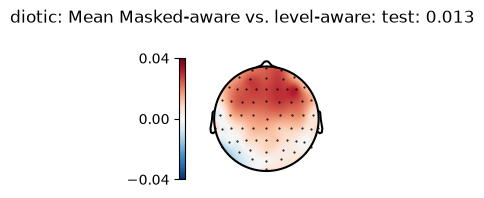

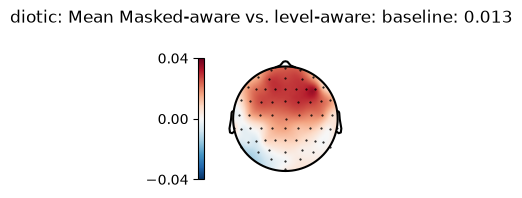

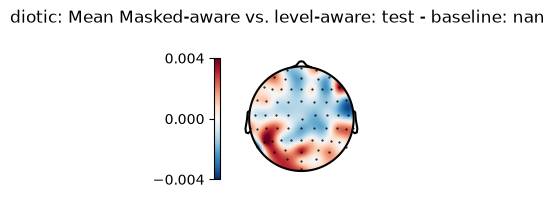

In [60]:
# Masked-aware vs. level-aware (diotic)
# Brodbeck et al. 2020 ran this comparison too: the ignored-speaker-aware model still beat the loudness-only model, t = 9.21, p < .001 - the masking effect isn't just about volume.
data, diff, result = compute_direct_comparison(FULL_MASKED, LEVEL_AWARE, 'diotic')
show_topomap_trio(data, diff, result, 'Masked-aware vs. level-aware', 'diotic', None)

In [61]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked-aware vs. level-aware (diotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .516>

Masked-aware vs. level-aware (diotic): ROI model comparison t(12) = -0.578, p = 0.7130


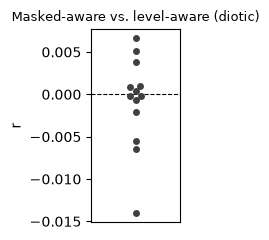

In [62]:
p = show_subject_swarm(diff, 'Masked-aware vs. level-aware', 'diotic')